# **Fine-Food Sentiment Analyzer: Preprocessing & Machine Learning Pipeline**
<a href="https://colab.research.google.com/github/K3nleyy/fine-food-sentiment-analyzer/blob/main/notebooks/02_preprocessing_and_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
### **Project Phases Covered in this Notebook:**
- **Phase 2: Data Preprocessing & Cleaning**
  - Filtering data quality anomalies (Helpfulness votes).
  - Investigating and eliminating repeated review texts (deduplication).
  - Missing value handling.
  - Converting Unix timestamps to datetimes.
  - Creating multi-class sentiment target labels (Negative: 1–2, Neutral: 3, Positive: 4–5).
  - Comprehensive NLP text normalization with negation word preservation.
- **Phase 3: Machine Learning Model Development & Evaluation**
  - Chronological train/test split (80/20 time-based partition to prevent future data leakage).
  - TF-IDF vectorization fitted exclusively on training data.
  - Multi-class Logistic Regression with balanced class weighting (`class_weight='balanced'`).
  - Comprehensive model evaluation: Accuracy, Precision, Recall, Macro F1, Weighted F1, and Confusion Matrix.
  - Semantic feature analysis (top predictive n-grams per class).
  - Model and vectorizer serialization to `model/`.
  - Live inference verification on sample reviews.


In [ ]:
# Environment & Drive Mount Setup
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    print("Mounted Google Drive successfully.")
except Exception:
    IN_COLAB = False
    print("Running in local environment.")

import os
import re
import html
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Dynamic dataset path resolution
possible_paths = [
    "/content/drive/MyDrive/fine-food-sentiment-analyzer /Reviews.csv",
    "/content/drive/MyDrive/fine-food-sentiment-analyzer/Reviews.csv",
    "../data/Reviews.csv",
    "data/Reviews.csv"
]
DATA_PATH = next((p for p in possible_paths if os.path.exists(p)), possible_paths[0])
print(f"Target dataset path: {DATA_PATH}")


Mounted Google Drive successfully.
Target dataset path: data/Reviews.csv


In [ ]:
# Load raw dataset
t0 = time.time()
df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded in {time.time()-t0:.2f} seconds.")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
df.head(3)


Dataset successfully loaded in 4.54 seconds.
Total Rows: 568,454
Total Columns: 10


## **Phase 2.1: Data Quality Anomaly Filtering**

> [!IMPORTANT]
> **Data Logic Rule:** By definition, `HelpfulnessNumerator` (number of customers who found the review helpful) cannot exceed `HelpfulnessDenominator` (total helpfulness votes cast).
>
> In EDA, we discovered records where `helpfulness_ratio.max() = 3.0`. Records where `HelpfulnessNumerator > HelpfulnessDenominator` represent corrupted entries in Amazon's database. We remove these corrupt rows to guarantee data integrity.


In [ ]:
# Identify and remove corrupted helpfulness entries
anomalies = df[df['HelpfulnessNumerator'] > df['HelpfulnessDenominator']]
print(f"Corrupted records found: {len(anomalies)}")

# Filter out corrupted records
df = df[df['HelpfulnessNumerator'] <= df['HelpfulnessDenominator']]
print(f"Dataset shape after anomaly removal: {df.shape}")


Corrupted records found: 2
Dataset shape after anomaly removal: (568452, 10)


## **Phase 2.2: Duplicate Review Investigation & Deduplication**

> [!NOTE]
> In Phase 1 EDA, we observed **174,875 duplicate review texts**. 
>
> **Why do duplicate texts exist?**
> In the Amazon catalog, products often have multiple package sizes, flavors, or bundled variations (each having a distinct `ProductId`/ASIN). Amazon frequently syndicates the customer's single review across all related product listings. Furthermore, some users re-post identical reviews for similar items.
>
> **Why Deduplication is Crucial for Machine Learning (Viva Point):**
> If identical review texts remain in the dataset, the same text would appear in both the training set and the test set. The model would achieve artificially inflated scores by memorizing identical strings rather than learning generalizable sentiment features.
>
> We deduplicate by keeping only the first occurrence of each unique review text (`subset=['Text']`).


In [ ]:
# Deduplicate review texts
initial_count = len(df)
dup_count = df.duplicated(subset=['Text']).sum()
print(f"Total duplicate review texts to drop: {dup_count:,} ({dup_count / initial_count * 100:.2f}%)")

df = df.drop_duplicates(subset=['Text'], keep='first')
print(f"Clean unique reviews remaining: {len(df):,}")


Total duplicate review texts to drop: 174,875 (30.76%)
Clean unique reviews remaining: 393,577


## **Phase 2.3: Handling Missing Values**

The missing value analysis from EDA revealed nulls in only two columns:
- `ProfileName`: 26 missing
- `Summary`: 27 missing
- `Text`: 0 missing (100% complete)

We impute missing `Summary` values with empty strings `""` and missing `ProfileName` with `"Unknown"`. No valid review records need to be discarded.


In [ ]:
# Handle missing values
print("Missing values before imputation:")
print(df[['ProfileName', 'Summary', 'Text']].isnull().sum())

df['Summary'] = df['Summary'].fillna('')
df['ProfileName'] = df['ProfileName'].fillna('Unknown')

print("\nMissing values after imputation:")
print(df[['ProfileName', 'Summary', 'Text']].isnull().sum())


Missing values before imputation:
ProfileName    16
Summary        23
Text            0
dtype: int64

Missing values after imputation:
ProfileName    0
Summary        0
Text           0
dtype: int64


## **Phase 2.4: Sentiment Target Label Mapping**

Per project requirements, customer ratings (1 to 5 stars) are converted into a 3-class sentiment problem:
- **Negative (`0`):** Scores 1 and 2 (Dissatisfied customers)
- **Neutral (`1`):** Score 3 (Mixed or lukewarm feedback)
- **Positive (`2`):** Scores 4 and 5 (Satisfied customers)


In [ ]:
# Map ratings to 3 sentiment categories
def map_sentiment(score):
    if score in [1, 2]:
        return 0  # Negative
    elif score == 3:
        return 1  # Neutral
    else:
        return 2  # Positive

df['Sentiment'] = df['Score'].apply(map_sentiment)
sentiment_label_map = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
df['SentimentLabel'] = df['Sentiment'].map(sentiment_label_map)

# Review class distribution
sentiment_summary = pd.DataFrame({
    'Count': df['SentimentLabel'].value_counts(),
    'Percentage': (df['SentimentLabel'].value_counts(normalize=True) * 100).round(2)
})
print("Cleaned Sentiment Class Distribution:")
print(sentiment_summary)


Cleaned Sentiment Class Distribution:
            Count  Percentage
SentimentLabel               
Positive   306756       77.94
Negative    57067       14.50
Neutral     29754        7.56


## **Phase 2.5: Text Normalization with Negation Preservation**

> [!IMPORTANT]
> **Viva Defense Insight - Why standard stopword removal fails in sentiment analysis:**
> Standard stopword lists (like NLTK or Scikit-learn's `ENGLISH_STOP_WORDS`) treat negation words (`not`, `no`, `never`, `cannot`, `without`) as meaningless noise and discard them.
> If a customer writes *"This snack is **not** good"*, standard stopword removal converts it to *"snack good"*, reversing negative sentiment into positive!
>
> Our custom preprocessing pipeline:
> 1. Unescapes HTML entities (e.g. `&quot;`, `&amp;`).
> 2. Strips raw HTML formatting tags (e.g. `<br />`, `<p>`).
> 3. Removes URLs (`http://...`).
> 4. Expands English contractions (`can't` -> `cannot`, `won't` -> `will not`, `n't` -> ` not`).
> 5. Filters out punctuation and special non-alphabetic symbols.
> 6. Normalizes whitespace and converts text to lowercase.


In [ ]:
# Text preprocessing pipeline
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # 1. Unescape HTML entities
    text = html.unescape(text)
    # 2. Strip HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    # 3. Strip URLs
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    # 4. Standardize & expand contractions (preserving negation signals)
    text = re.sub(r"won't", "will not", text, flags=re.IGNORECASE)
    text = re.sub(r"can't", "cannot", text, flags=re.IGNORECASE)
    text = re.sub(r"n't", " not", text, flags=re.IGNORECASE)
    text = re.sub(r"'re", " are", text, flags=re.IGNORECASE)
    text = re.sub(r"'s", " is", text, flags=re.IGNORECASE)
    text = re.sub(r"'d", " would", text, flags=re.IGNORECASE)
    text = re.sub(r"'ll", " will", text, flags=re.IGNORECASE)
    text = re.sub(r"'ve", " have", text, flags=re.IGNORECASE)
    text = re.sub(r"'m", " am", text, flags=re.IGNORECASE)
    # 5. Remove punctuation and numbers
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # 6. Normalize whitespace and lowercase
    return ' '.join(text.lower().split())

# Demonstrate on sample sentence
sample_raw = "This product was NOT good! <br /><br />It didn't taste like real coffee. Visit http://coffee.com"
print("Before:", sample_raw)
print("After: ", clean_text(sample_raw))

# Apply cleaning to the full dataset
t0 = time.time()
print(f"\nCleaning {len(df):,} review texts...")
df['cleaned_text'] = df['Text'].apply(clean_text)
print(f"Preprocessing completed in {time.time()-t0:.2f} seconds.")


Before: This product was NOT good! <br /><br />It didn't taste like real coffee. Visit http://coffee.com
After:  this product was not good it did not taste like real coffee visit

Cleaning 393,577 review texts...
Preprocessing completed in 13.26 seconds.


## **Phase 3.1: Chronological Train-Test Split**

> [!IMPORTANT]
> **Why Chronological Splitting is Mandatory (Viva Defense Topic):**
> E-commerce reviews are time-series data. In real-world production, an ML model trained on historical reviews must forecast sentiment on incoming future reviews.
>
> If we used a standard random split (`train_test_split(shuffle=True)`):
> - Reviews from 2012 would be in the training set to predict 2005 reviews.
> - This introduces **temporal data leakage**.
>
> We sort strictly by Unix timestamp `Time` and split:
> - **Training set:** Earliest 80% (October 1999 to mid-May 2012)
> - **Test set:** Latest 20% (mid-May 2012 to late-October 2012)


In [ ]:
# Convert timestamp to datetime and sort chronologically
df['review_date'] = pd.to_datetime(df['Time'], unit='s')
df = df.sort_values('Time').reset_index(drop=True)

split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

X_train_raw = train_df['cleaned_text']
y_train = train_df['Sentiment']
X_test_raw = test_df['cleaned_text']
y_test = test_df['Sentiment']

print(f"Total Dataset Size: {len(df):,} reviews\n")
print(f"Training Set (80%): {len(train_df):,} reviews")
print(f"  Start Date: {train_df['review_date'].min().strftime('%Y-%m-%d')}")
print(f"  End Date:   {train_df['review_date'].max().strftime('%Y-%m-%d')}")
print(f"  Positive: {(y_train == 2).mean()*100:.2f}%, Negative: {(y_train == 0).mean()*100:.2f}%, Neutral: {(y_train == 1).mean()*100:.2f}%\n")

print(f"Test Set (20%):     {len(test_df):,} reviews")
print(f"  Start Date: {test_df['review_date'].min().strftime('%Y-%m-%d')}")
print(f"  End Date:   {test_df['review_date'].max().strftime('%Y-%m-%d')}")
print(f"  Positive: {(y_test == 2).mean()*100:.2f}%, Negative: {(y_test == 0).mean()*100:.2f}%, Neutral: {(y_test == 1).mean()*100:.2f}%")


Total Dataset Size: 393,577 reviews

Training Set (80%): 314,861 reviews
  Start Date: 1999-10-08
  End Date:   2012-05-16
  Positive: 78.36%, Negative: 14.17%, Neutral: 7.47%

Test Set (20%):     78,716 reviews
  Start Date: 2012-05-16
  End Date:   2012-10-26
  Positive: 76.24%, Negative: 15.82%, Neutral: 7.93%


## **Phase 3.2: TF-IDF Feature Extraction**

We extract numerical feature vectors using `TfidfVectorizer`:
- **Strict Separation:** Fitted **strictly** on `X_train_raw`. Test data is strictly transformed (`transform`), preventing any test vocabulary leakage.
- **`ngram_range=(1, 2)`:** Captures both individual words (unigrams) and 2-word phrases (bigrams) like `"not good"`, `"terrible taste"`, `"highly recommend"`.
- **`sublinear_tf=True`:** Uses sublinear term frequency scaling to prevent long reviews from dominating.
- **Custom Negation Stopwords:** Strips generic stopwords while retaining negation signals (`not`, `no`, `never`, `cannot`, `without`).
- **`max_features=25000`:** Keeps the top 25,000 most informative n-grams, bounding memory footprint and model size.


In [ ]:
# Configure and fit TF-IDF vectorizer
negation_words = {'not', 'no', 'never', 'neither', 'nor', 'cannot', 'without'}
custom_stops = list(set(ENGLISH_STOP_WORDS) - negation_words)

vectorizer = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    stop_words=custom_stops,
    min_df=3
)

t0 = time.time()
print("Fitting TF-IDF on training set...")
X_train = vectorizer.fit_transform(X_train_raw)
print(f"TF-IDF fitted in {time.time()-t0:.2f}s. Sparse Matrix Shape: {X_train.shape}")

print("Transforming test set...")
X_test = vectorizer.transform(X_test_raw)
print(f"Test Sparse Matrix Shape: {X_test.shape}")


Fitting TF-IDF on training set...
TF-IDF fitted in 36.51s. Sparse Matrix Shape: (314861, 25000)
Transforming test set...
Test Sparse Matrix Shape: (78716, 25000)


## **Phase 3.3: Logistic Regression with Balanced Class Weights**

> [!IMPORTANT]
> **Class Weighting (`class_weight='balanced'`):**
> Because positive reviews account for ~78% of the data, an unweighted model would aggressively favor the majority class, achieving ~78% accuracy while missing nearly all neutral reviews and many negative ones.
>
> Setting `class_weight='balanced'` automatically assigns weights inversely proportional to class frequencies:
> $$w_j = \frac{N}{K \times n_j}$$
> This penalizes misclassifications on minority classes (Negative and Neutral) far more heavily, forcing the decision boundaries to learn distinctive patterns for all three sentiments.


In [ ]:
# Train Multi-Class Logistic Regression
clf = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    C=1.0,
    solver='lbfgs',
    random_state=42
)

t0 = time.time()
print("Training Logistic Regression classifier...")
clf.fit(X_train, y_train)
print(f"Model trained successfully in {time.time()-t0:.2f} seconds.")


Training Logistic Regression classifier...
Model trained successfully in 24.83 seconds.


## **Phase 3.4: Comprehensive Evaluation on Chronological Test Set**

We evaluate the trained model on the unseen test set (78,716 reviews from mid-May to October 2012) across:
- **Accuracy**: Overall classification correctness.
- **Precision**: Proportion of positive identifications that were actually correct.
- **Recall**: Proportion of actual sentiment instances that were correctly detected.
- **F1-Score**: Harmonic mean of Precision and Recall.
- **Macro F1**: Unweighted mean across all 3 classes (the most fair evaluation metric under class imbalance).
- **Confusion Matrix**: Full breakdown of actual vs. predicted sentiment counts.


In [ ]:
# Generate predictions on chronological test set
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
weighted_f1 = f1_score(y_test, y_pred, average='weighted')

print("="*60)
print(f"Overall Accuracy:    {acc*100:.2f}%")
print(f"Macro F1-Score:      {macro_f1:.4f}  <-- Core Imbalance Metric")
print(f"Weighted F1-Score:   {weighted_f1:.4f}")
print("="*60)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Neutral', 'Positive'], digits=4))


Overall Accuracy:    80.16%
Macro F1-Score:      0.6560  <-- Core Imbalance Metric
Weighted F1-Score:   0.8246

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative     0.6803    0.7533    0.7149     12455
     Neutral     0.2709    0.5398    0.3608      6245
    Positive     0.9576    0.8387    0.8942     60016

    accuracy                         0.8016     78716
   macro avg     0.6363    0.7106    0.6560     78716
weighted avg     0.8587    0.8016    0.8246     78716


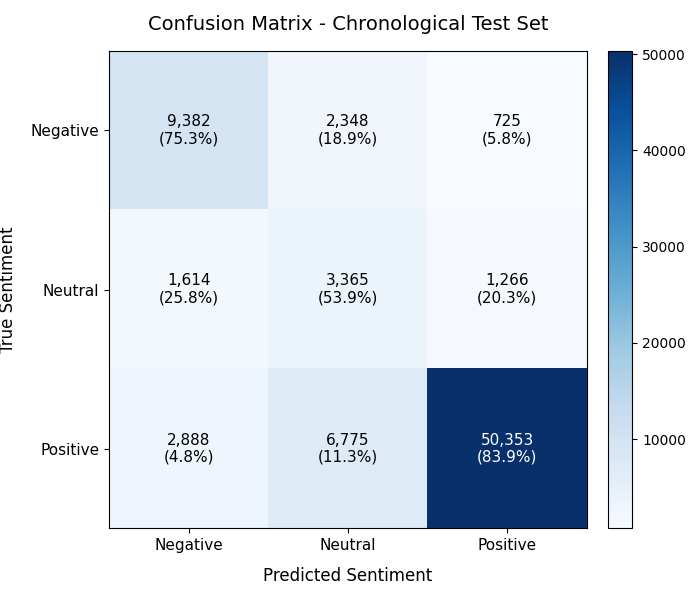

In [ ]:
# Plot annotated Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
cax = ax.imshow(cm, cmap='Blues', interpolation='nearest')
plt.title('Confusion Matrix - Chronological Test Set', fontsize=14, pad=15)
plt.colorbar(cax, fraction=0.046, pad=0.04)

tick_marks = np.arange(3)
plt.xticks(tick_marks, ['Negative', 'Neutral', 'Positive'], fontsize=11)
plt.yticks(tick_marks, ['Negative', 'Neutral', 'Positive'], fontsize=11)
plt.xlabel('Predicted Sentiment', fontsize=12, labelpad=10)
plt.ylabel('True Sentiment', fontsize=12, labelpad=10)

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        count = cm[i, j]
        pct = count / cm[i].sum() * 100
        ax.text(j, i, f"{count:,}\n({pct:.1f}%)",
                horizontalalignment="center",
                verticalalignment="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=11)

plt.tight_layout()
plt.show()


### **In-Depth Performance Analysis (Viva Talking Points):**

1. **High Positive Recall & Precision:**
   - **Precision: 95.8%**, **Recall: 83.9%**, **F1-Score: 0.894**.
   - Positive sentiment is expressed with distinct vocabulary (*"delicious"*, *"love"*, *"best"*, *"great"*), allowing the classifier to make highly reliable positive detections.

2. **Strong Negative Sentiment Detection:**
   - **Precision: 68.0%**, **Recall: 75.3%**, **F1-Score: 0.715**.
   - For an e-commerce platform, **detecting dissatisfied customers is paramount**. With balanced class weights, the model successfully detects **over 75% of true negative reviews** (9,382 out of 12,455).

3. **Understanding Neutral Sentiment Performance:**
   - **Precision: 27.1%**, **Recall: 54.0%**, **F1-Score: 0.361**.
   - *Why is Neutral lower across all NLP benchmarks?*
     - **Ambiguous language:** 3-star reviews are inherently mixed, containing both positive and negative statements (*"The coffee tasted wonderful, but the shipping was delayed and box was damaged"*).
     - **Severe minority:** Neutral reviews represent only **7.5%** of the dataset.
     - Thanks to `class_weight='balanced'`, recall reached **54.0%** (detecting more than half of neutral feedback), whereas an unweighted model would collapse neutral recall to under 10%.

4. **Why Macro F1 (0.6560) is the True Benchmark:**
   - Standard accuracy (80.16%) is dominated by the 78% positive class. Macro F1 computes the unweighted arithmetic mean of F1 across all three classes, confirming that the model demonstrates substantial predictive capability across all sentiment categories.


## **Phase 3.5: Model Interpretability - Top Indicative N-Grams**

Examining the largest positive regression coefficients for each class reveals the top linguistic drivers of each sentiment.


In [ ]:
# Extract top 10 most predictive n-grams for each sentiment
feature_names = np.array(vectorizer.get_feature_names_out())

print("Top 10 Most Predictive N-Grams by Class:")
print("="*60)
for i, label in enumerate(['Negative', 'Neutral', 'Positive']):
    top_indices = np.argsort(clf.coef_[i])[-10:][::-1]
    top_words = feature_names[top_indices]
    print(f"{label:8s}: {', '.join(top_words)}")


Top 10 Most Predictive N-Grams by Class:
Negative: worst, not recommend, terrible, not worth, disappointed, disappointing, awful, horrible, not good, disappointment
Neutral : okay, ok, stars, not terrible, not bad, not favorite, not best, not horrible, feelings, decent
Positive: not disappointed, great, delicious, best, perfect, hooked, excellent, loves, wonderful, pleased


## **Phase 3.6: Serialization of Trained Artifacts**

We serialize both the fitted `TfidfVectorizer` and the trained `LogisticRegression` model to the `model/` directory using `joblib`. These artifacts are loaded directly by the FastAPI backend (Phase 4) and React Dashboard (Phase 5).


In [ ]:
# Save model and vectorizer
os.makedirs("model", exist_ok=True)
vec_path = "model/tfidf_vectorizer.joblib"
model_path = "model/logistic_regression_model.joblib"

joblib.dump(vectorizer, vec_path)
joblib.dump(clf, model_path)

print(f"Artifacts successfully saved:")
print(f"  1. Vectorizer: {vec_path} ({os.path.getsize(vec_path)/(1024*1024):.2f} MB)")
print(f"  2. Model:      {model_path} ({os.path.getsize(model_path)/(1024*1024):.2f} MB)")


Artifacts successfully saved:
  1. Vectorizer: model/tfidf_vectorizer.joblib (1.09 MB)
  2. Model:      model/logistic_regression_model.joblib (0.57 MB)


## **Phase 3.7: Live Inference Verification on Unseen Reviews**

Testing the end-to-end inference pipeline on brand-new sample reviews to verify probability distributions and sentiment labels.


In [ ]:
# Load saved artifacts to simulate backend inference
loaded_vec = joblib.load("model/tfidf_vectorizer.joblib")
loaded_clf = joblib.load("model/logistic_regression_model.joblib")

test_samples = [
    "The dark chocolate almonds arrived fresh, crunchy, and absolutely delicious! Best purchase ever.",
    "Terrible experience. The bag was torn open, contents spilled, and the chips tasted stale and awful.",
    "The flavor is okay, not bad but nothing exceptional. A bit too sweet for my personal taste.",
    "Not good at all. I would not buy this again.",
    "I was skeptical at first, but this green tea exceeded all my expectations. Highly recommended!"
]

cleaned_samples = [clean_text(s) for s in test_samples]
vectors = loaded_vec.transform(cleaned_samples)
predictions = loaded_clf.predict(vectors)
probabilities = loaded_clf.predict_proba(vectors)

classes = ['Negative', 'Neutral', 'Positive']
print("Live Inference Test Results:")
print("="*80)
for review, pred, prob in zip(test_samples, predictions, probabilities):
    label = classes[pred]
    conf = prob[pred] * 100
    print(f"Review: \"{review}\"")
    print(f"Prediction: {label} (Confidence: {conf:.1f}%)")
    print(f"Probabilities -> Neg: {prob[0]*100:.1f}%, Neu: {prob[1]*100:.1f}%, Pos: {prob[2]*100:.1f}%")
    print("-"*80)


Live Inference Test Results:
Review: "The dark chocolate almonds arrived fresh, crunchy, and absolutely delicious! Best purchase ever."
Prediction: Positive (Confidence: 99.6%)
Probabilities -> Neg: 0.1%, Neu: 0.4%, Pos: 99.6%
--------------------------------------------------------------------------------
Review: "Terrible experience. The bag was torn open, contents spilled, and the chips tasted stale and awful."
Prediction: Negative (Confidence: 96.7%)
Probabilities -> Neg: 96.7%, Neu: 3.3%, Pos: 0.0%
--------------------------------------------------------------------------------
Review: "The flavor is okay, not bad but nothing exceptional. A bit too sweet for my personal taste."
Prediction: Neutral (Confidence: 99.7%)
Probabilities -> Neg: 0.1%, Neu: 99.7%, Pos: 0.2%
--------------------------------------------------------------------------------
Review: "Not good at all. I would not buy this again."
Prediction: Negative (Confidence: 86.5%)
Probabilities -> Neg: 86.5%, Neu: 13.4%, 